> **Recorded research notebook.** Executed outputs are retained from the completed study. Empirical recomputation requires the separately retained input snapshots described in `data/README.md`. Run `python scripts/reproduce_public.py` for checks and a synthetic demonstration using only this public repository. Historical publication-stage notes below describe the notebook execution date; the final PDF is now in `paper/final/Information-Diffusion-Final-Paper.pdf`.

# 05 · Chronological transfer and information sets

Development covers 2018–2022, validation covers 2023, and the later period covers 2024–2025. A model fitted only on development events is compared with the development-mean return baseline. The time split prevents fitting coefficients on later outcomes, but cannot undo the earlier inspection of the incorrectly aligned run. All corrected later checks are **post-audit chronological transfer**.

The relevant question is whether a fixed conditional relationship travels across time. It is not whether a strategy earns trading profits. The surprise uses information through +20 minutes; a model of the first 20 minutes is retrospective even when its coefficients come from earlier calendar years.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'diffusion/common.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from diffusion.common import ROOT, design, sha256
from diffusion.reporting import table
from diffusion.presentation import show_table, show_json, show_figure, show_plot, equation
pd.set_option('display.max_columns', 12)
print('Project:', ROOT.name)
print('Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.')

Project: Information-Diffusion-Research
Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.


In [2]:
freeze=json.loads((ROOT/'protocol/corrected-model-freeze.json').read_text())
changed=[p for p,digest in freeze['files'].items() if sha256(ROOT/p)!=digest]
assert not changed
print('Corrected freeze timestamp:',freeze['released_utc'])
print('Frozen analytical files verified:',len(freeze['files']))
print(freeze['notice'])
models=json.loads((ROOT/'outputs/models/development-predictions.json').read_text())
for model in models.values():
    assert all('2018'<=eid[-10:-6]<='2022' for eid in model['training_ids'])
print('Every stored prediction model uses development event IDs only.')

Corrected freeze timestamp: 2026-10-16T20:01:04.966664+00:00
Frozen analytical files verified: 16
Post-audit chronological transfer. Original held-out outcomes were examined before discovering the clock problem. Corrected development model frozen before recalculating corrected held-out outcomes; no untouched holdout, prospective blinding or external preregistration claimed.
Every stored prediction model uses development event IDs only.


In [3]:
from diffusion.empirical import data_for,panel,return_between
from diffusion.statistics import paired_mse_summary
bars,events=data_for(['holdout'])
x,y,m,p=panel(bars,events,'SPX','Statements')
model=models['Statements|SPX|cumulative_20']
actual=return_between(p,0,20)
prediction=x@model['coef']
baseline=np.full(len(m),model['baseline'])
fresh=paired_mse_summary(actual,prediction,baseline)
stored=table('transfer-holdout.csv').query("asset=='SPX' and event_type=='Statements' and target=='cumulative_20'").iloc[0]
for field in ['model_mse','baseline_mse','difference','difference_ci_low','difference_ci_high']:
    assert np.isclose(fresh[field],stored[field])
show_json(fresh)
equation(15)

{
  "n": 16,
  "model_mse": 949.165557352397,
  "baseline_mse": 957.963624329004,
  "difference": -8.798066976607117,
  "difference_ci_low": -1075.4100460415477,
  "difference_ci_high": 965.8536329674455,
  "units": "squared basis points; negative difference favours surprise model"
}

Equation (15). Paired prediction-loss difference.
\Delta_{\mathrm{MSE}}=\frac1N\sum_{e=1}^{N}\left[(Y_e-\widehat Y_e)^2-(Y_e-\widehat Y_e^{\,0})^2\right]
Negative values favour the frozen surprise model over the development-mean baseline.

target,n,model_mse,baseline_mse,difference,difference_ci_low,difference_ci_high
cumulative_20,16,949.166,957.964,-8.798,"-1,075.410",965.854
late_5_20,16,531.366,502.773,28.593,-81.875,166.889
post_observation_20_25,16,126.447,62.653,63.794,-18.462,177.199


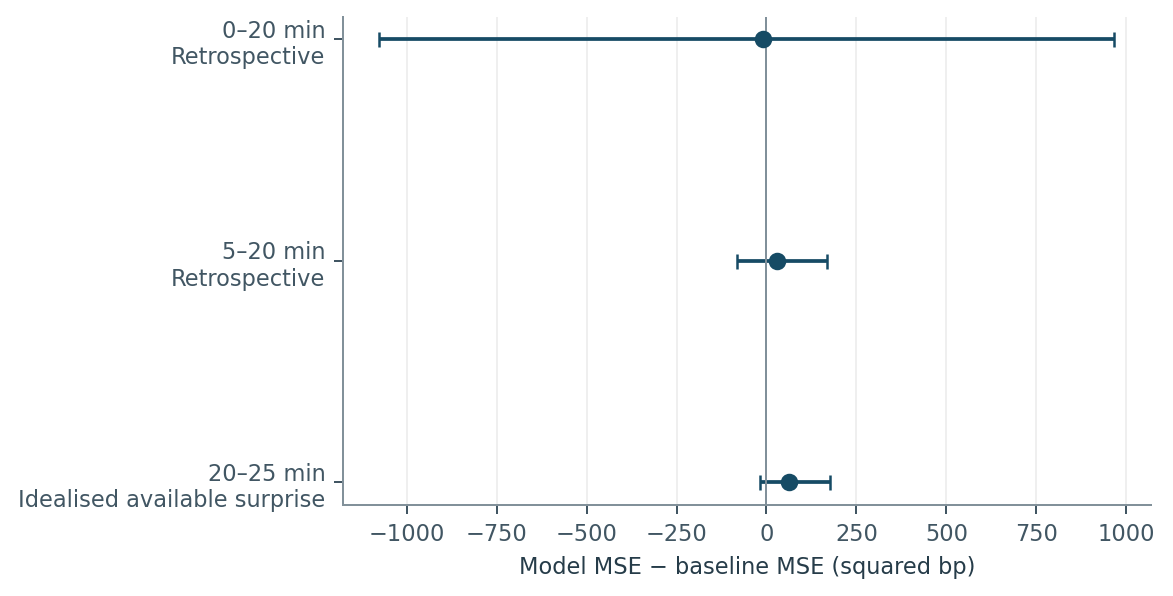

Figure 8. Frozen corrected-development predictions on later statements. Negative differences favour the surprise model. This post-audit transfer follows the A02 clock repair, not an untouched holdout; within-window inputs are retrospective and +20-minute publication latency is not modelled.

event_type,asset,accepted,planned,sample_gate
Minutes,EURUSD,4,8,False
Minutes,NSX,4,8,False
Minutes,SPX,4,8,False
Statements,EURUSD,3,8,False
Statements,NSX,3,8,False
Statements,SPX,3,8,False


In [4]:
transfer=table('transfer-holdout.csv').query("asset=='SPX' and event_type=='Statements'")
show_table(transfer[['target','n','model_mse','baseline_mse','difference','difference_ci_low','difference_ci_high']], 'Table N05.1. Later-period paired prediction-loss comparison, after the clock audit.')
assert ((transfer.difference_ci_low<0)&(transfer.difference_ci_high>0)).all()
show_figure(8)
show_table(table('coverage.csv').query("phase=='validation'")[['event_type','asset','accepted','planned','sample_gate']], 'Table N05.2. Why the 2023 validation period cannot support the declared response estimation.')

## Interpretation

For later statements, 0–20-minute MSE is 949.17 bp² for the surprise model and 957.96 bp² for the baseline. The paired difference is −8.80 bp² with a very broad interval spanning zero. The 5–20 and 20–25 models have larger point-estimate losses than their baselines, and their difference intervals also include zero. The study therefore finds no convincing predictive improvement across these three targets.

The first two targets overlap the rate-surprise observation window. The final target is temporally separate but assumes the completed surprise is available instantly at +20. It omits publication delay, transaction costs, spreads, executable prices and trade sizing. Neither numerical error reductions nor nominal p-values would establish a viable trading rule.

The historical split is a useful stability check, not a substitute for a genuinely untouched future sample after the clock rule has been fixed. No failed period or inconvenient event is removed to strengthen the transfer result.

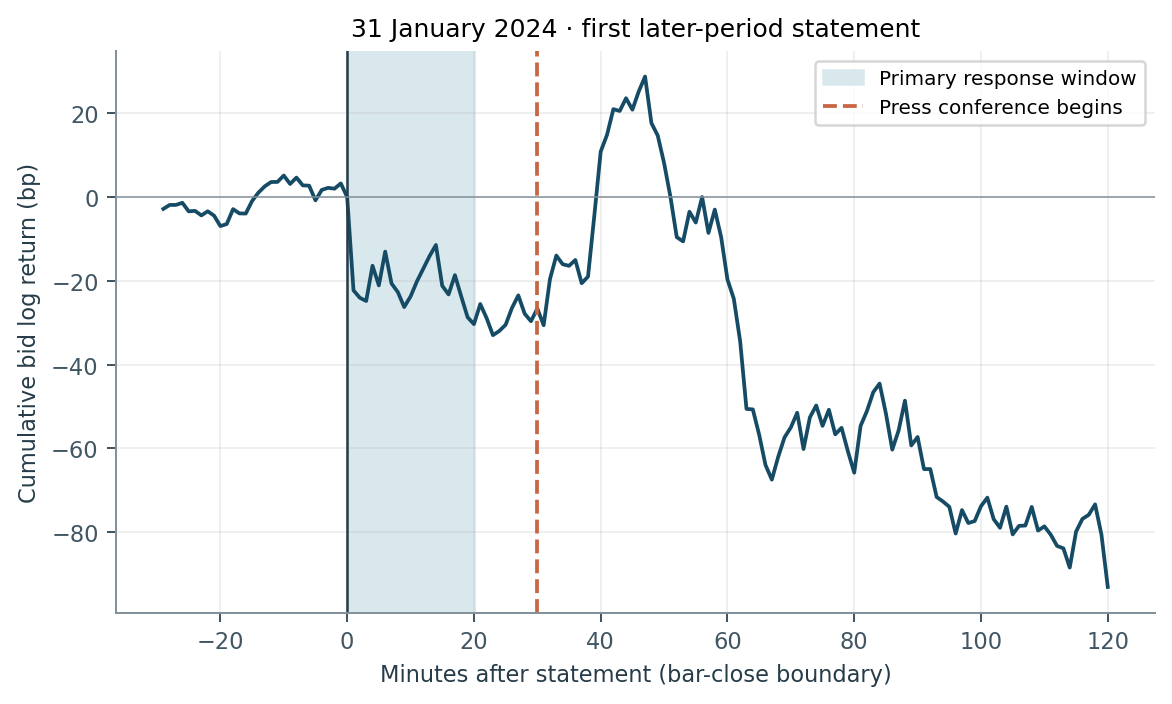

Figure 11. The first later-period statement, selected by date. The subsequent press conference introduces additional information; movements after that release cannot be attributed solely to delayed incorporation of the statement.

Sequential release warning: the press conference may add new information from +30 minutes.
The primary +20-minute horizon avoids attributing that later release to statement diffusion.


In [5]:
show_figure(11)
print('Sequential release warning: the press conference may add new information from +30 minutes.')
print('The primary +20-minute horizon avoids attributing that later release to statement diffusion.')

## Milestone outcome

Chronological predictions and their paired loss intervals are reproduced from frozen coefficients. The information timing and the compromised original holdout are explicit. Later-period performance remains inconclusive, rather than a claimed forecasting success.